In [2]:
import yfinance as yf
import pandas as pd


start_date = '2015-01-01'
end_date = '2026-09-26'
tickers = ['NOVO-B.CO', 'DSV.CO', 'MAERSK-B.CO', 'VWS.CO', 'DANSKE.CO', 'CARL-B.CO', 'PNDORA.CO', 'COLO-B.CO', 'TRYG.CO', 'GMAB.CO', '^OMXC25']
data = yf.download(tickers=tickers, start=start_date, end=end_date)


/Users/mortenkleist/Documents/Quant_pipeline/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/mortenkleist/Documents/Quant_pipeline/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/mortenkleist/Documents/Quant_pipeline/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#d

In [3]:


prices = data['Close']
print(prices.shape)
print(prices.isna().sum())
print(prices.apply(lambda s: s.first_valid_index()))

(2934, 11)
Ticker
CARL-B.CO        1
COLO-B.CO        1
DANSKE.CO        1
DSV.CO           1
GMAB.CO          1
MAERSK-B.CO      1
NOVO-B.CO        1
PNDORA.CO        1
TRYG.CO          1
VWS.CO           1
^OMXC25        559
dtype: int64
Ticker
CARL-B.CO     2015-01-02
COLO-B.CO     2015-01-02
DANSKE.CO     2015-01-02
DSV.CO        2015-01-02
GMAB.CO       2015-01-02
MAERSK-B.CO   2015-01-02
NOVO-B.CO     2015-01-02
PNDORA.CO     2015-01-02
TRYG.CO       2015-01-02
VWS.CO        2015-01-02
^OMXC25       2016-12-19
dtype: datetime64[s]


In [4]:

volume = data["Volume"]
dollar_vol = (data["Close"] * volume).tail(60).mean()
print(dollar_vol.sort_values())

prices.to_csv('../data/prices.csv')

Ticker
TRYG.CO        8.853988e+07
COLO-B.CO      1.436460e+08
CARL-B.CO      1.797908e+08
PNDORA.CO      2.032687e+08
GMAB.CO        2.322993e+08
MAERSK-B.CO    2.969638e+08
DANSKE.CO      3.059679e+08
VWS.CO         4.097555e+08
DSV.CO         7.213832e+08
NOVO-B.CO      1.322843e+09
^OMXC25        2.869979e+10
dtype: float64


In [5]:
import numpy as np
prices = pd.read_csv('../data/prices.csv',index_col=0, parse_dates=True)

prices = prices.dropna()
nan_rows = prices[prices.isna().any(axis=1)]
print(nan_rows)
print(prices.isna().sum(axis=1).value_counts())

Empty DataFrame
Columns: [CARL-B.CO, COLO-B.CO, DANSKE.CO, DSV.CO, GMAB.CO, MAERSK-B.CO, NOVO-B.CO, PNDORA.CO, TRYG.CO, VWS.CO, ^OMXC25]
Index: []
0    2374
Name: count, dtype: int64


## 1.2

In [6]:
rng = np.random.default_rng(0)
r = rng.normal(0.0005, 0.01, size=252)   # fake daily simple returns

print(np.prod(1 + r))      # compounded over a year
print(np.sum(r))           # sum of simple returns
print(np.exp(np.sum(np.log(1 + r))))

1.1050301834990122
0.11282620751448513
1.105030183499011


In [7]:
import numpy as np
import pandas as pd

def simple_returns(prices: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    """Daily simple returns: P_t / P_{t-1} - 1.

    The first row is NaN because there is no previous price.
    NaNs in the input propagate to the output.
    """
    
    return prices / prices.shift(1) - 1 

def log_returns(prices: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    """Daily log returns: ln(P_t / P_{t-1})."""
     
    return np.log(prices) - np.log(prices.shift(1))

def cumulative_returns(returns, log: bool = False):
    """Growth of 1 unit invested..."""
    if log:
        return np.exp(returns.cumsum()) 
    else:
         
        return (returns+1).cumprod(skipna=True) 

In [8]:

prices = pd.Series([100.0, np.nan, 99.0, 105.0])
prices.ffill(inplace=True)
r = simple_returns(prices)
print(r)
print(cumulative_returns(r))

0         NaN
1    0.000000
2   -0.010000
3    0.060606
dtype: float64
0     NaN
1    1.00
2    0.99
3    1.05
dtype: float64


In [9]:
def annualized_return(returns: pd.DataFrame | pd.Series, period: int = 250, log: bool = False):
    """Geometric average growth per year
    (end__value / begin_value)^(1/n) - 1
    n: # years held, n = len(returns)/250 (250 becuase using copenhagen nasdaq)
    """
    n = len(returns) / period
    cum_returns = cumulative_returns(returns=returns, log=log)
    return (cum_returns.iloc[-1])**(1/n) -1

r = pd.Series([0.001] * 250)
print(annualized_return(r))
print(1.001**250 -1)

0.2838650304502217
0.2838650304502215


In [10]:
r = pd.Series([0.001] * 252)
print(annualized_return(r, period=252))
print(1.001**252 - 1)

0.2864340443761524
0.28643404437615216


In [11]:
def annualized_volatility(log_return: pd.DataFrame | pd.Series, period: int = 250):
    """Annualized volatility
    Varince of sum of independent variables with var sigma^2:
        X = sum(X_i), i in [1, 2, 3, ..., n]
        Var(X) = Var(sum(X_i)) = sum(Var(X_i)) = sum(sigma^2) = n * sigma^2
        => std(X) = sqrt(n) * sigma
    
    Input: log_returns is the daily log returns
    Choosing n: # days per year gives annualized volatility ie. ddof = 0
    Output: sqrt(n)*log_returns.std(ddof=n) is the annualized volatility
    """
    n = period
    return np.sqrt(n) * log_return.std(ddof=1)

def drawdown_series(curve: pd.DataFrame | pd.Series):
    running_max = curve.cummax()
    return curve/(running_max) - 1

def max_drawdown(curve: pd.DataFrame | pd.Series):
    '''
    Returns the maximum drawdown using negative magnitudes
    '''
    drawdown = drawdown_series(curve)
    return drawdown.min()

log_returns_ = pd.Series([0.01, -0.01]*252)
print(log_returns_.std(ddof=0)*np.sqrt(252))
print(annualized_volatility(log_returns_, 252))

0.15874507866387547
0.1589027986020968


In [12]:
r = pd.Series([np.nan, -0.2, 0.1])
curve = cumulative_returns(r)
print(curve)
print(max_drawdown(curve))

0     NaN
1    0.80
2    0.88
dtype: float64
0.0


In [13]:
import numpy as np
import pandas as pd

def simple_returns(prices: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    """Daily simple returns: P_t / P_{t-1} - 1.

    prices are forward-filled first, so NaNs in the middle become zero returns, and the first row is NaN
    """
    filled_prices = prices.ffill()
    return filled_prices / filled_prices.shift(1) - 1 

def log_returns(prices: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    """Daily log returns: ln(P_t / P_{t-1}).
    prices are forward-filled first, so NaNs in the middle become zero returns, and the first row is NaN"""

    filled_prices = prices.ffill()
    return np.log(filled_prices) - np.log(filled_prices.shift(1))

def cumulative_returns(returns, log: bool = False):
    """output is a growth factor starting at 1.0, missing returns are treated as 0"""
    if log:
        cum_return = np.exp((returns.fillna(0)).cumsum()) 
        return cum_return
    else:
        cum_return = (returns.fillna(0)+1).cumprod()
        return cum_return 

def annualized_return(returns: pd.DataFrame | pd.Series, period: int = 250, log: bool = False):
    """Geometric average growth per year
    (gross return)^(1/n) - 1
    n: # years held, n = len(returns)/250 (250 becuase using copenhagen nasdaq)
    
    """
    n = returns.count() / period
    cum_returns = cumulative_returns(returns=returns, log=log)
    return (cum_returns.iloc[-1])**(1/n) -1

def annualized_volatility(log_return: pd.DataFrame | pd.Series, period: int = 250):
    """Annualized volatility
    Varince of sum of independent variables with var sigma^2:
        X = sum(X_i), i in [1, 2, 3, ..., n]
        Var(X) = Var(sum(X_i)) = sum(Var(X_i)) = sum(sigma^2) = n * sigma^2
        => std(X) = sqrt(n) * sigma
    
    Input: log_returns is the daily log returns
    Choosing n: # days per year gives annualized volatility ie. ddof = 0
    Output: sqrt(n)*log_returns.std(ddof=n) is the annualized volatility
    """
    n = period
    return np.sqrt(n) * log_return.std()

def drawdown_series(curve: pd.DataFrame | pd.Series):
    """
    expects a curve with base 1.0, returns values ≤ 0
    """
    running_max = curve.cummax()
    return curve/(running_max) - 1

def max_drawdown(curve: pd.DataFrame | pd.Series):
    '''
    Returns the maximum drawdown using negative magnitudes
    '''
    drawdown = drawdown_series(curve)
    return drawdown.min()

In [14]:
r = pd.Series([np.nan, -0.2, 0.1])
curve = cumulative_returns(r)
print(curve)
print(max_drawdown(curve))

0    1.00
1    0.80
2    0.88
dtype: float64
-0.19999999999999996


In [15]:
r = pd.Series([np.nan, 0.2, -0.5, 0.5])

print((r + 1).cumprod())
print(r.fillna(0))
print((r.fillna(0) + 1).cumprod())

0    NaN
1    1.2
2    0.6
3    0.9
dtype: float64
0    0.0
1    0.2
2   -0.5
3    0.5
dtype: float64
0    1.0
1    1.2
2    0.6
3    0.9
dtype: float64


In [16]:
prices = pd.Series([100.0, 110.0, 99.0])
returns = simple_returns(prices)
print(cumulative_returns(returns))

0    1.00
1    1.10
2    0.99
dtype: float64


In [17]:
prices = pd.read_csv('../data/prices.csv',index_col=0, parse_dates=True)

log_returns_ = log_returns(prices)
curve = cumulative_returns(log_returns_, log=True)

anu_returns = annualized_return(log_returns_, log=True)
anu_vol = annualized_volatility(log_returns_)
max_dd = max_drawdown(curve)
idx = drawdown_series(curve).idxmin()


summary_data = {
    "Annualized Returns": anu_returns,
    "Annualized Volatility": anu_vol,   
    "Return/vol": anu_returns/anu_vol,
    "Max Drawdown": max_dd,
    "Max Drawdown date": idx,
}

# 4. Lav det om til et nyt DataFrame med de helt samme kolonnenavne
df_summary = pd.DataFrame(summary_data)

print(df_summary.round(3))

             Annualized Returns  Annualized Volatility  Return/vol  \
CARL-B.CO                 0.078                  0.224       0.348   
COLO-B.CO                 0.006                  0.251       0.023   
DANSKE.CO                 0.123                  0.274       0.450   
DSV.CO                    0.177                  0.287       0.617   
GMAB.CO                   0.167                  0.345       0.485   
MAERSK-B.CO               0.153                  0.381       0.403   
NOVO-B.CO                 0.082                  0.327       0.252   
PNDORA.CO                 0.074                  0.405       0.183   
TRYG.CO                   0.074                  0.201       0.369   
VWS.CO                    0.139                  0.411       0.339   
^OMXC25                   0.064                  0.170       0.378   

             Max Drawdown Max Drawdown date  
CARL-B.CO          -0.395        2025-01-13  
COLO-B.CO          -0.639        2026-06-30  
DANSKE.CO          -0

/var/folders/lv/2db0g4qn03gb0w_tzbqp3xtr0000gn/T/ipykernel_33127/1553159280.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df_summary.round(3))


## 1.3

In [18]:
prices = pd.read_csv('../data/prices.csv',index_col=0, parse_dates=True)
log_returns_ = log_returns(prices).dropna()
max5_returns = log_returns_.apply(lambda x: x.nlargest(5))
print(max5_returns)

            CARL-B.CO  COLO-B.CO  DANSKE.CO    DSV.CO   GMAB.CO  MAERSK-B.CO  \
Date                                                                           
2017-08-09        NaN        NaN        NaN       NaN       NaN          NaN   
2017-08-24        NaN        NaN        NaN       NaN  0.107050          NaN   
2018-02-22        NaN        NaN        NaN       NaN  0.163500          NaN   
2018-04-17        NaN        NaN        NaN       NaN  0.083785          NaN   
2018-05-03        NaN   0.062509        NaN       NaN       NaN          NaN   
2019-02-05        NaN        NaN        NaN       NaN       NaN          NaN   
2019-08-08   0.106820        NaN        NaN       NaN       NaN          NaN   
2019-08-21        NaN        NaN        NaN       NaN       NaN          NaN   
2019-09-09        NaN        NaN   0.086683       NaN       NaN          NaN   
2019-10-23        NaN        NaN        NaN       NaN       NaN          NaN   
2020-03-13        NaN        NaN        

In [19]:
from scipy.stats import skew, kurtosis
prices = pd.read_csv('../data/prices.csv',index_col=0, parse_dates=True)
log_returns_ = log_returns(prices).dropna()

means = log_returns_.mean()
stds = log_returns_.std()
skews = log_returns_.skew()
kurtosiss = log_returns_.kurtosis()

summary_data = {
    "Mean": means,
    "Standard dev": stds,   
    "Skewness": skews,
    "Kurtosis": kurtosiss,    
}

df_summary = pd.DataFrame(summary_data).T

print(df_summary)

              CARL-B.CO  COLO-B.CO  DANSKE.CO    DSV.CO   GMAB.CO  \
Mean           0.000256   0.000051   0.000432  0.000577  0.000280   
Standard dev   0.013957   0.015925   0.017607  0.018573  0.021094   
Skewness      -0.137720  -0.263511  -0.340826 -0.554651 -0.543211   
Kurtosis       5.478365   4.215653   5.743594  7.275381  8.820404   

              MAERSK-B.CO  NOVO-B.CO  PNDORA.CO   TRYG.CO    VWS.CO   ^OMXC25  
Mean             0.000650   0.000378   0.000097  0.000349  0.000379  0.000249  
Standard dev     0.024458   0.020885   0.026460  0.012193  0.026720  0.010765  
Skewness        -0.349979  -1.870478  -0.711534 -0.636972  0.020225 -0.535109  
Kurtosis         3.617991  24.059981  12.229812  6.657578  6.677075  3.451572  


Text(0.5, 1.0, 'Vestas log_return')

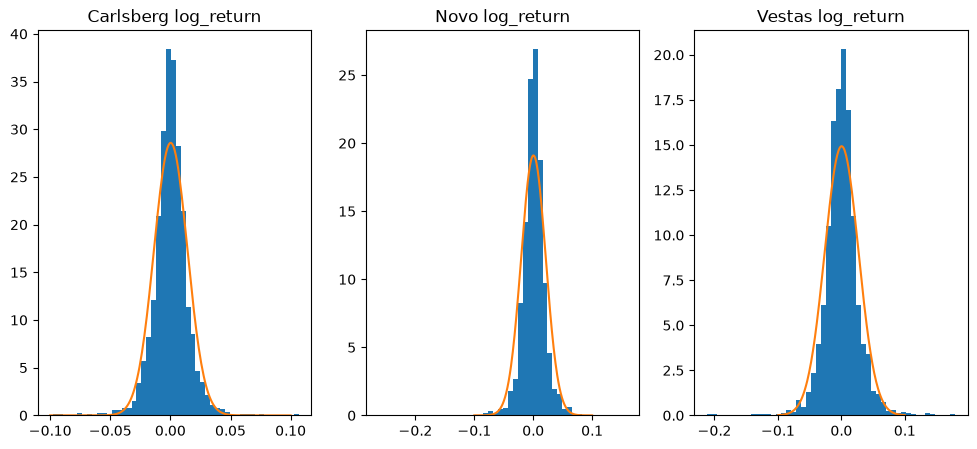

In [27]:
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot

fig, ax = plt.subplots(1, 3, figsize=(12,5))

x = np.linspace(-0.1, 0.1, 200)
ax[0].hist(log_returns_['CARL-B.CO'], bins=50, density=True)
ax[0].plot(x, norm.pdf(x, 0.000256, 0.013957))
ax[0].set_title('Carlsberg log_return')

ax[1].hist(log_returns_['NOVO-B.CO'], bins=50, density=True)
ax[1].plot(x, norm.pdf(x, 0.000378, 0.020885))
ax[1].set_title('Novo log_return')

ax[2].hist(log_returns_['VWS.CO'], bins=50, density=True)
ax[2].plot(x, norm.pdf(x, 0.000379, 0.026720))
ax[2].set_title('Vestas log_return')
